# 03 — Détection d'anomalies : SVM

**Responsable : Membre 3** · Cible : `label` (0 = normal, 1 = anomalie) · Entrée : `data/processed/*` (notebook 01)

## Workflow
1. Chargement des splits ; pourquoi le SVM exige **standardisation + log1p**
2. **Baseline** SVM linéaire
3. **Équilibrage** (CV) et **réglage** de `C` pour le SVM linéaire
4. **SVM à noyau RBF** : réglage de `C` et `gamma` (grille) — entraîné sur un sous-échantillon car coût ≈ O(n²)
5. **Approximation du noyau RBF (Nyström) + SVM linéaire** : version passe-à-l'échelle entraînée sur *tout* le train
6. Comparaison des 3 variantes en validation, choix du modèle retenu
7. **Calibration** du seuil (marge de décision) et des probabilités (Platt / isotonique) sur la validation
8. **Évaluation finale unique sur le test**
9. Interprétation (coefficients, permutation), analyse des erreurs, sauvegarde

> Un SVM ne sort pas de probabilités mais une **marge** signée (`decision_function`). Le seuil naturel est 0 ; il peut être déplacé et les scores
> peuvent être transformés en probabilités par **Platt scaling**.

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_validate, learning_curve, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, brier_score_loss
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.max_columns", 40)
RS = U.RANDOM_STATE
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["label"].to_numpy(), y_va["label"].to_numpy(), y_te["label"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})

{'train': (110132, 33), 'valid': (36711, 33), 'test': (36711, 33)}


## 1. Pipeline SVM

Le SVM est **sensible à l'échelle** (distance / produit scalaire) : les octets (jusqu'à 10⁹) écraseraient les drapeaux 0/1. Le préprocesseur applique donc
`imputation → log1p → StandardScaler` aux numériques (`scale=True`) et un one-hot aux catégorielles, tous ajustés sur le train uniquement.

In [2]:
SAMPLERS = {"Aucun": lambda: None, "class_weight": lambda: None, "Sous-échantillonnage": lambda: RandomUnderSampler(random_state=RS),
            "Sur-échantillonnage": lambda: RandomOverSampler(random_state=RS), "SMOTE": lambda: SMOTE(k_neighbors=5, random_state=RS)}
def make_pipe(kind="linear", strategy="class_weight", **p):
    steps = [("pre", U.make_preprocessor(NUM, CAT, scale=True))]
    sampler = SAMPLERS[strategy]()
    if sampler is not None: steps.append(("sampler", sampler))
    cw = "balanced" if strategy == "class_weight" else None
    if kind == "linear":
        steps.append(("svm", LinearSVC(dual="auto", max_iter=20000, class_weight=cw, random_state=RS, **p)))
    elif kind == "rbf":
        steps.append(("svm", SVC(kernel="rbf", cache_size=800, class_weight=cw, random_state=RS, **p)))
    elif kind == "nystroem":
        gamma, C = p.pop("gamma"), p.pop("C", 1.0)
        steps.append(("nys", Nystroem(kernel="rbf", gamma=gamma, n_components=p.pop("n_components", 300), random_state=RS)))
        steps.append(("svm", LinearSVC(dual="auto", max_iter=20000, C=C, class_weight=cw, random_state=RS)))
    return ImbPipeline(steps)
score_fn = lambda m, X: m.decision_function(X)        # marge signée : > 0 => anomalie
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(50000, random_state=RS).index; Xs, ys = X_train.loc[sub], ytr[sub]

## 2. Baseline
SVM linéaire, `C = 1`, sans équilibrage.

In [3]:
t0 = time.time(); base = make_pipe("linear", "Aucun").fit(X_train, ytr); t_base = time.time() - t0
s_base = score_fn(base, X_valid); base_valid = U.binary_metrics(yva, (s_base > 0).astype(int), scores=s_base)
print(f"Temps : {t_base:.1f}s"); display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps : 2.3s


,accuracy,balanced_accuracy,precision,recall,f1,mcc,tn,fp,fn,tp,fpr,fnr,roc_auc,pr_auc
baseline (validation),0.9950,0.9931,0.9969,0.9966,0.9968,0.9859,8299.0000,88.0000,95.0000,28229.0000,0.0105,0.0034,0.9990,0.9997


## 3. SVM linéaire : équilibrage et réglage de `C`
Même protocole que pour le Random Forest (CV stratifiée à 3 plis, rééchantillonnage refait dans chaque pli), pour des comparaisons équitables.

,f1_macro,balanced_acc,pr_auc,recall,precision,std_f1_macro,temps_s
stratégie,,,,,,,
Aucun,0.9929,0.9926,0.9997,0.9970,0.9965,0.0007,2.0683
class_weight,0.9923,0.9941,0.9997,0.9949,0.9980,0.0006,1.8169
Sous-échantillonnage,0.9922,0.9942,0.9997,0.9947,0.9981,0.0005,1.5269
Sur-échantillonnage,0.9920,0.9938,0.9997,0.9948,0.9979,0.0004,2.3792
SMOTE,0.9924,0.9941,0.9997,0.9951,0.9980,0.0004,3.5082



=> Stratégie retenue : Aucun


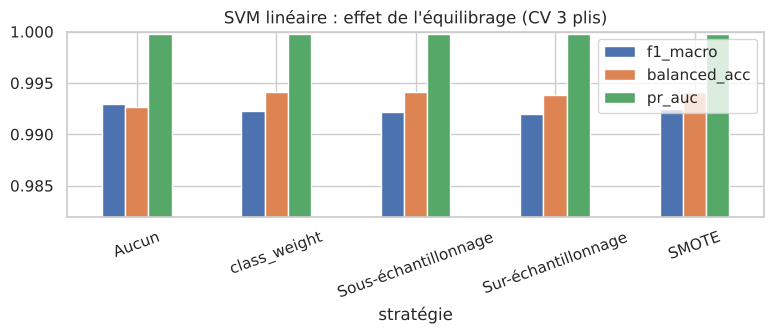

In [4]:
rows = []
for name in SAMPLERS:
    t0 = time.time()
    r = cross_validate(make_pipe("linear", name), Xs, ys, cv=cv, n_jobs=1,
                       scoring={"f1_macro": "f1_macro", "balanced_acc": "balanced_accuracy", "pr_auc": "average_precision", "recall": "recall", "precision": "precision"})
    rows.append({"stratégie": name, **{k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")}, "std_f1_macro": r["test_f1_macro"].std(), "temps_s": time.time() - t0})
bal = pd.DataFrame(rows).set_index("stratégie"); display(bal.round(4))
best_strategy = bal["f1_macro"].idxmax(); print(f"\n=> Stratégie retenue : {best_strategy}")
fig, ax = plt.subplots(figsize=(8, 3.5)); bal[["f1_macro", "balanced_acc", "pr_auc"]].plot(kind="bar", ax=ax); ax.set_ylim(bal[["f1_macro", "balanced_acc", "pr_auc"]].min().min() - .01, 1.0)
ax.set_title("SVM linéaire : effet de l'équilibrage (CV 3 plis)"); ax.tick_params(axis="x", rotation=20); plt.tight_layout(); U.savefig(fig, "03_balancing_cv"); plt.show()

,param_svm__C,mean_train_score,mean_test_score,std_test_score
9,0.0010,0.9813,0.9811,0.0017
4,0.0240,0.9913,0.9911,0.0008
5,0.0356,0.9920,0.9918,0.0006
8,0.1172,0.9932,0.9929,0.0006
1,0.3857,0.9934,0.9929,0.0006
3,0.8532,0.9933,0.9929,0.0007
2,9.2367,0.9933,0.9929,0.0006
7,13.7382,0.9933,0.9929,0.0006
0,45.2035,0.9933,0.9929,0.0006
6,67.2336,0.9933,0.9929,0.0006


Meilleur C (linéaire) : 45.2035


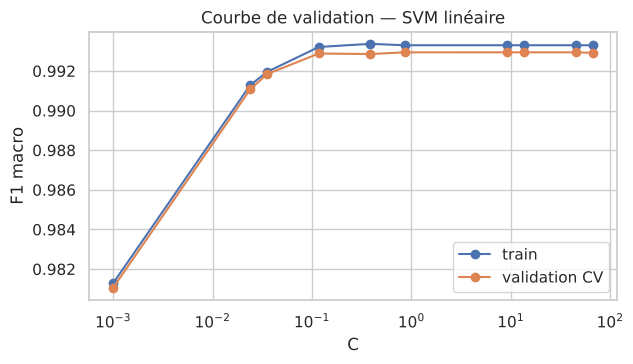

In [5]:
search = RandomizedSearchCV(make_pipe("linear", best_strategy), {"svm__C": np.logspace(-3, 2, 30)}, n_iter=10, cv=cv, scoring="f1_macro", random_state=RS, n_jobs=1, refit=False, return_train_score=True)
search.fit(Xs, ys); res = pd.DataFrame(search.cv_results_).sort_values("param_svm__C")
display(res[["param_svm__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(4))
best_C = float(search.best_params_["svm__C"]); print("Meilleur C (linéaire) :", round(best_C, 4))
fig, ax = plt.subplots(figsize=(6.5, 3.8)); ax.semilogx(res.param_svm__C.astype(float), res.mean_train_score, "o-", label="train"); ax.semilogx(res.param_svm__C.astype(float), res.mean_test_score, "o-", label="validation CV")
ax.set(xlabel="C", ylabel="F1 macro", title="Courbe de validation — SVM linéaire"); ax.legend(); plt.tight_layout(); U.savefig(fig, "03_validation_curve_C"); plt.show()

## 4. SVM à noyau RBF
Le noyau RBF capture des frontières **non linéaires** que le SVM linéaire ne peut pas représenter. Le coût d'apprentissage est ≈ O(n²) à O(n³) :
on entraîne sur un **sous-échantillon stratifié** (par type) et on règle `C` et `gamma` par validation croisée sur un sous-échantillon plus petit.
- `C` : pénalité des erreurs (grand = marge étroite, risque de surapprentissage)
- `gamma` : portée d'un point (grand = frontière très locale)

Grille RBF : 22s


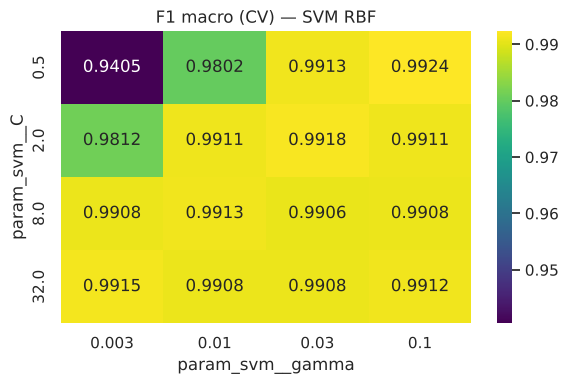

Meilleurs (C, gamma) : {'C': 0.5, 'gamma': 0.1}


In [6]:
tune_idx, _ = train_test_split(X_train.index, train_size=8000, stratify=y_tr["type"], random_state=RS)
fit_idx, _ = train_test_split(X_train.index, train_size=20000, stratify=y_tr["type"], random_state=RS)
grid = GridSearchCV(make_pipe("rbf", best_strategy), {"svm__C": [0.5, 2, 8, 32], "svm__gamma": [0.003, 0.01, 0.03, 0.1]}, cv=cv, scoring="f1_macro", n_jobs=1, return_train_score=True, refit=False)
t0 = time.time(); grid.fit(X_train.loc[tune_idx], ytr[tune_idx]); print(f"Grille RBF : {time.time()-t0:.0f}s")
g = pd.DataFrame(grid.cv_results_); piv = g.pivot(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score").astype(float)
fig, ax = plt.subplots(figsize=(6, 4)); sns.heatmap(piv, annot=True, fmt=".4f", cmap="viridis", ax=ax); ax.set_title("F1 macro (CV) — SVM RBF"); plt.tight_layout(); U.savefig(fig, "03_rbf_grid"); plt.show()
best_rbf = {"C": float(grid.best_params_["svm__C"]), "gamma": float(grid.best_params_["svm__gamma"])}; print("Meilleurs (C, gamma) :", best_rbf)

## 5. Approximation du noyau RBF (Nyström) + SVM linéaire
`Nystroem` projette les données dans un espace de 300 dimensions où le produit scalaire approche le noyau RBF ; un SVM **linéaire** y est appris sur
**tout le train** en quelques secondes. C'est le compromis classique entre la puissance du noyau RBF et le coût du SVM exact.

In [7]:
variants, fit_times = {}, {}
for name, builder in {"SVM linéaire": lambda: make_pipe("linear", best_strategy, C=best_C),
                      "SVM RBF (20k lignes)": lambda: make_pipe("rbf", best_strategy, **best_rbf),
                      "RBF Nyström + linéaire": lambda: make_pipe("nystroem", best_strategy, gamma=best_rbf["gamma"], C=best_rbf["C"])}.items():
    t0 = time.time(); m = builder()
    (m.fit(X_train.loc[fit_idx], ytr[fit_idx]) if "RBF (" in name else m.fit(X_train, ytr)); fit_times[name] = time.time() - t0; variants[name] = m
    print(f"{name:26s} entraîné en {fit_times[name]:6.1f}s")

SVM linéaire               entraîné en    2.0s


SVM RBF (20k lignes)       entraîné en    1.1s


RBF Nyström + linéaire     entraîné en   16.1s


## 6. Comparaison des variantes (validation) et choix du modèle

,accuracy,precision,recall,f1,mcc,fpr,fnr,roc_auc,pr_auc,fit_s
SVM linéaire,0.9950,0.9969,0.9966,0.9968,0.9858,0.0106,0.0034,0.9990,0.9997,1.9596
SVM RBF (20k lignes),0.9956,0.9971,0.9972,0.9972,0.9876,0.0098,0.0028,0.9993,0.9998,1.1259
RBF Nyström + linéaire,0.9921,0.9977,0.9921,0.9948,0.9777,0.0079,0.0079,0.9993,0.9998,16.0960


=> Modèle SVM retenu (meilleur F1 en validation) : SVM RBF (20k lignes)


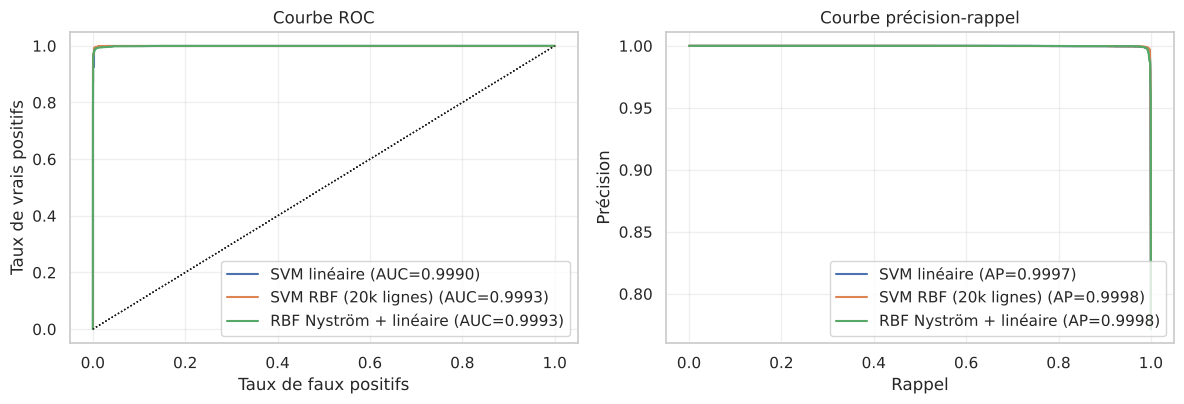

In [8]:
sv = {n: score_fn(m, X_valid) for n, m in variants.items()}
cmp_ = pd.DataFrame({n: {**U.binary_metrics(yva, (s > 0).astype(int), scores=s), "fit_s": fit_times[n]} for n, s in sv.items()}).T
display(cmp_[["accuracy", "precision", "recall", "f1", "mcc", "fpr", "fnr", "roc_auc", "pr_auc", "fit_s"]].round(4))
retained = cmp_["f1"].idxmax(); print(f"=> Modèle SVM retenu (meilleur F1 en validation) : {retained}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for n, s in sv.items(): U.plot_roc_pr(yva, s, n, axes=axes)
plt.tight_layout(); U.savefig(fig, "03_variants_roc_pr"); plt.show()

F1 train = 0.9970 | F1 validation = 0.9972
              precision    recall  f1-score   support

      normal     0.9906    0.9902    0.9904      8387
    anomalie     0.9971    0.9972    0.9972     28324

    accuracy                         0.9956     36711
   macro avg     0.9938    0.9937    0.9938     36711
weighted avg     0.9956    0.9956    0.9956     36711



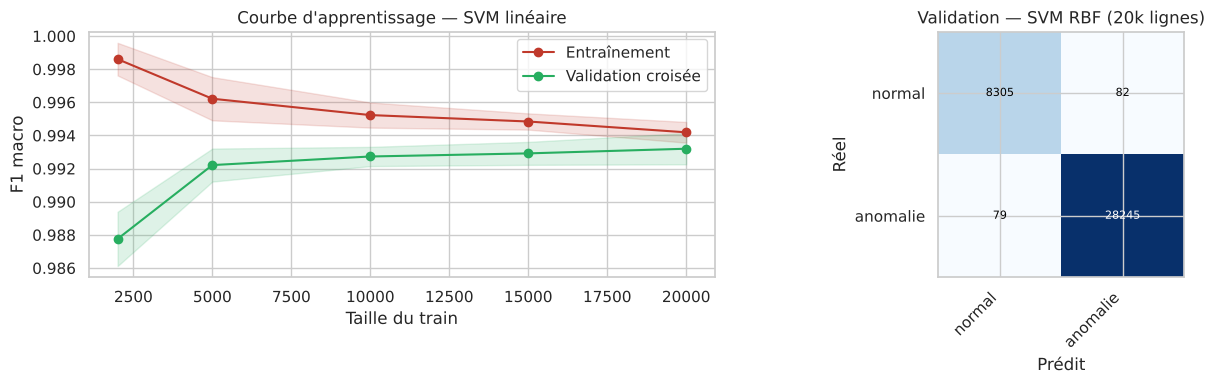

In [9]:
final = variants[retained]; s_tr, s_va = score_fn(final, X_train), sv[retained]
print(f"F1 train = {f1_score(ytr, (s_tr>0).astype(int)):.4f} | F1 validation = {f1_score(yva, (s_va>0).astype(int)):.4f}")
print(classification_report(yva, (s_va > 0).astype(int), target_names=["normal", "anomalie"], digits=4))
sizes, tr_sc, va_sc = learning_curve(make_pipe("linear", best_strategy, C=best_C), Xs.iloc[:30000], ys[:30000], cv=cv, scoring="f1_macro", train_sizes=[.1, .25, .5, .75, 1.0], n_jobs=1, random_state=RS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for sc, lab, c in [(tr_sc, "Entraînement", "#c0392b"), (va_sc, "Validation croisée", "#27ae60")]:
    axes[0].plot(sizes, sc.mean(1), "o-", label=lab, color=c); axes[0].fill_between(sizes, sc.mean(1)-sc.std(1), sc.mean(1)+sc.std(1), alpha=.15, color=c)
axes[0].set(xlabel="Taille du train", ylabel="F1 macro", title="Courbe d'apprentissage — SVM linéaire"); axes[0].legend()
U.plot_confusion(confusion_matrix(yva, (s_va > 0).astype(int)), ["normal", "anomalie"], f"Validation — {retained}", ax=axes[1]); plt.tight_layout(); U.savefig(fig, "03_learning_curve"); plt.show()

## 7. Calibration

### 7.a Seuil de décision (sur la marge)
Le seuil naturel est 0. On cherche celui qui maximise le F1 sur la **validation**.

Seuil optimal sur la marge = -0.0268 (F1 validation = 0.9971) ; seuil par défaut = 0


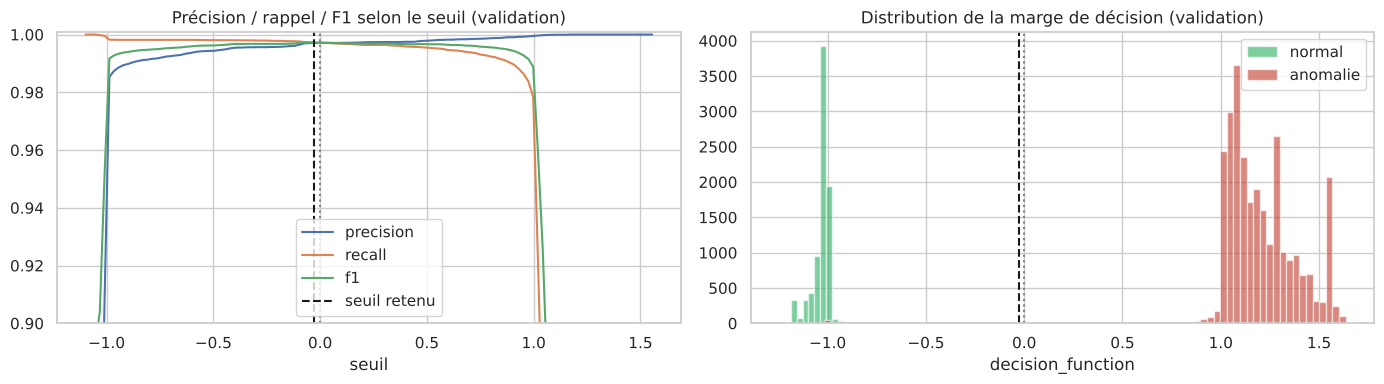

In [10]:
thr, f1_thr = U.best_f1_threshold(yva, s_va); print(f"Seuil optimal sur la marge = {thr:.4f} (F1 validation = {f1_thr:.4f}) ; seuil par défaut = 0")
grid_t = np.linspace(np.quantile(s_va, .02), np.quantile(s_va, .98), 120)
cur = pd.DataFrame({"seuil": grid_t, **{m: [fn(yva, (s_va >= t).astype(int), zero_division=0) for t in grid_t] for m, fn in [("precision", precision_score), ("recall", recall_score), ("f1", f1_score)]}})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cur.set_index("seuil").plot(ax=axes[0]); axes[0].axvline(thr, color="k", ls="--", label="seuil retenu"); axes[0].axvline(0, color="grey", ls=":"); axes[0].set_ylim(.9, 1.001); axes[0].set_title("Précision / rappel / F1 selon le seuil (validation)"); axes[0].legend()
for lab, c in [(0, "#27ae60"), (1, "#c0392b")]: axes[1].hist(s_va[yva == lab], bins=80, alpha=.6, color=c, label=["normal", "anomalie"][lab])
axes[1].axvline(0, color="grey", ls=":"); axes[1].axvline(thr, color="k", ls="--"); axes[1].set(title="Distribution de la marge de décision (validation)", xlabel="decision_function"); axes[1].legend()
plt.tight_layout(); U.savefig(fig, "03_threshold_margin"); plt.show()

### 7.b Calibration des probabilités (Platt / isotonique)
Platt = régression logistique sur la marge ; isotonique = fonction monotone. Ajustés sur la **validation**, jugés sur le **test** (Brier + fiabilité).

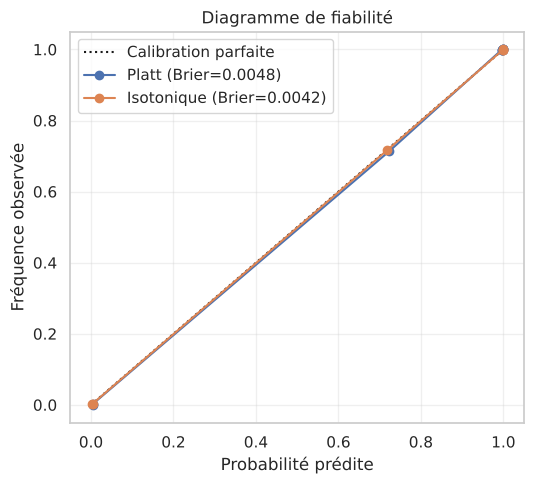

,Platt,Isotonique
Brier (test),0.0048,0.0042


Meilleur calibrateur : Isotonique ; seuil sur probabilité = 0.6596


In [11]:
s_te = score_fn(final, X_test)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(s_va.reshape(-1, 1), yva)
iso = IsotonicRegression(out_of_bounds="clip").fit(s_va, yva)
cal_te = {"Platt": platt.predict_proba(s_te.reshape(-1, 1))[:, 1], "Isotonique": iso.predict(s_te)}
cal_va = {"Platt": platt.predict_proba(s_va.reshape(-1, 1))[:, 1], "Isotonique": iso.predict(s_va)}
fig, ax = plt.subplots(figsize=(5.5, 5)); U.plot_calibration(yte, cal_te, ax=ax); plt.tight_layout(); U.savefig(fig, "03_calibration"); plt.show()
brier = pd.Series({k: brier_score_loss(yte, v) for k, v in cal_te.items()}, name="Brier (test)"); display(brier.to_frame().T.round(5))
best_cal = brier.idxmin(); thr_cal, _ = U.best_f1_threshold(yva, cal_va[best_cal]); print(f"Meilleur calibrateur : {best_cal} ; seuil sur probabilité = {thr_cal:.4f}")

## 8. Évaluation finale sur le test (une seule fois)
Le tableau officiel du notebook 06 utilise la ligne **« seuil calibré »**.

,accuracy,balanced_accuracy,precision,recall,f1,mcc,fpr,fnr,roc_auc,pr_auc,tn,fp,fn,tp
Marge > 0 (défaut),0.9946,0.9920,0.9962,0.9968,0.9965,0.9846,0.0128,0.0032,0.9992,0.9997,8280.0000,107.0000,92.0000,28232.0000
Seuil calibré (F1 valid),0.9946,0.9920,0.9962,0.9968,0.9965,0.9848,0.0128,0.0032,0.9992,0.9997,8280.0000,107.0000,90.0000,28234.0000
Probas calibrées (Isotonique),0.9947,0.9920,0.9962,0.9969,0.9965,0.9848,0.0128,0.0031,0.9992,0.9997,8280.0000,107.0000,89.0000,28235.0000


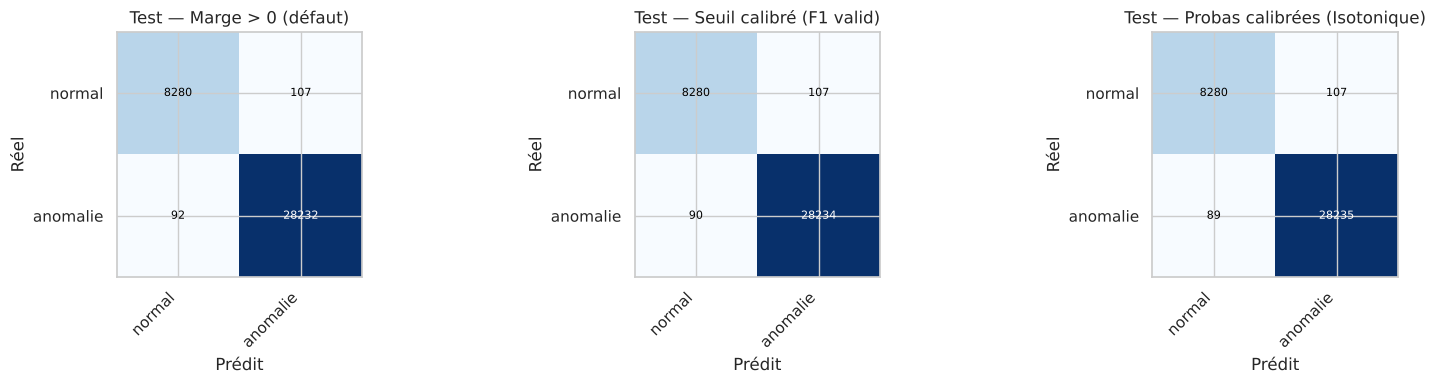

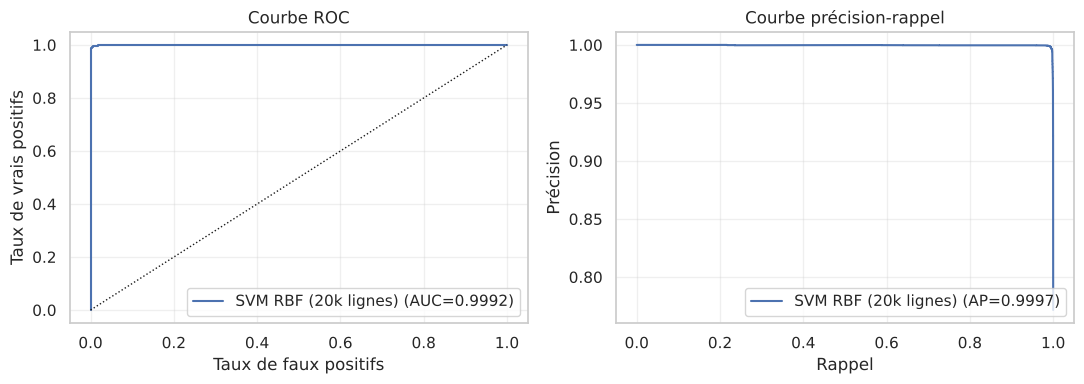

In [12]:
pred = {"Marge > 0 (défaut)": (s_te > 0).astype(int), "Seuil calibré (F1 valid)": (s_te >= thr).astype(int), f"Probas calibrées ({best_cal})": (cal_te[best_cal] >= thr_cal).astype(int)}
test_tbl = pd.DataFrame({k: U.binary_metrics(yte, v, scores=s_te, proba=cal_te[best_cal] if "Probas" in k else None) for k, v in pred.items()}).T
display(test_tbl[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "mcc", "fpr", "fnr", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (k, v) in zip(axes, pred.items()): U.plot_confusion(confusion_matrix(yte, v), ["normal", "anomalie"], f"Test — {k}", ax=ax)
plt.tight_layout(); U.savefig(fig, "03_test_confusions"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); U.plot_roc_pr(yte, s_te, retained, axes=axes); plt.tight_layout(); U.savefig(fig, "03_test_roc_pr"); plt.show()

## 9. Interprétation et analyse des erreurs

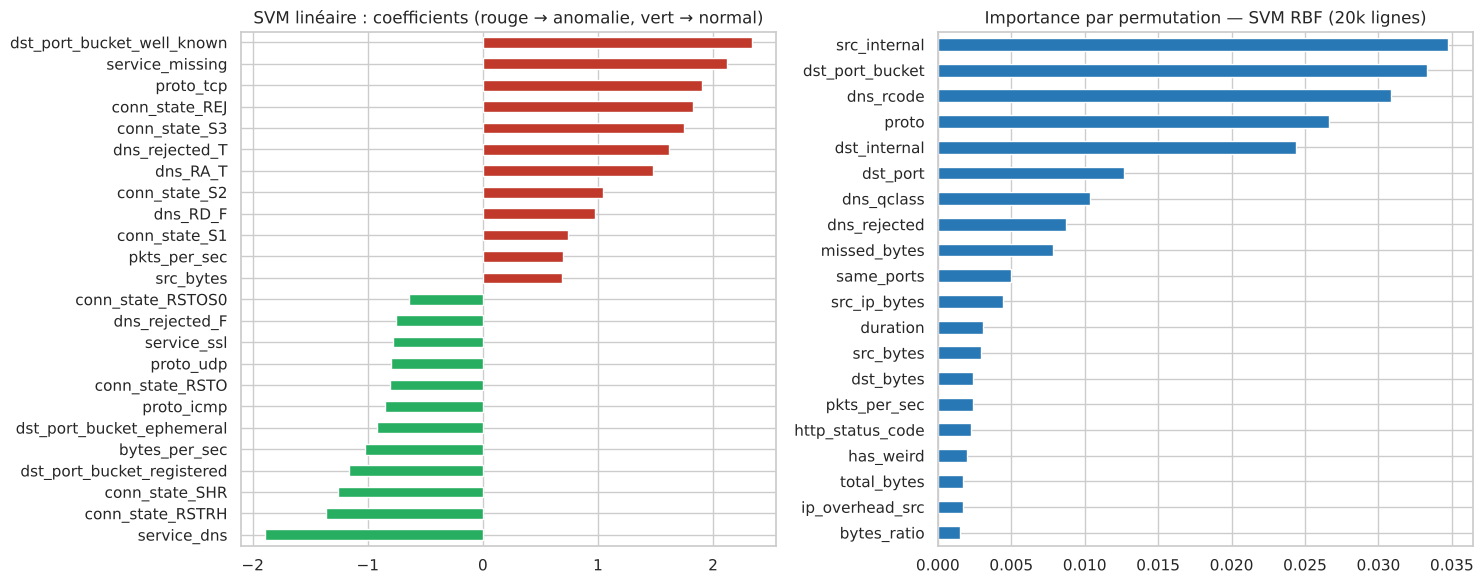

In [13]:
lin = variants["SVM linéaire"]; names = U.feature_names(lin.named_steps["pre"]); coef = pd.Series(lin.named_steps["svm"].coef_.ravel(), index=names).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pd.concat([coef.head(12), coef.tail(12)]).plot(kind="barh", ax=axes[0], color=["#27ae60"] * 12 + ["#c0392b"] * 12); axes[0].set_title("SVM linéaire : coefficients (rouge → anomalie, vert → normal)")
sidx = X_valid.sample(6000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[sidx.to_numpy()], scoring="f1_macro", n_repeats=3, random_state=RS, n_jobs=1)
pd.Series(pi.importances_mean, index=X_valid.columns).sort_values().tail(20).plot(kind="barh", ax=axes[1], color="#2878b5"); axes[1].set_title(f"Importance par permutation — {retained}")
plt.tight_layout(); U.savefig(fig, "03_importances"); plt.show()

,n,erreurs,taux_erreur
type,,,
normal,8387,107,0.0128
scanning,3723,1,0.0003
dos,2935,8,0.0027
ddos,3997,55,0.0138
password,3970,5,0.0013
injection,3992,1,0.0003
xss,2904,5,0.0017
backdoor,3742,6,0.0016
ransomware,2853,1,0.0004


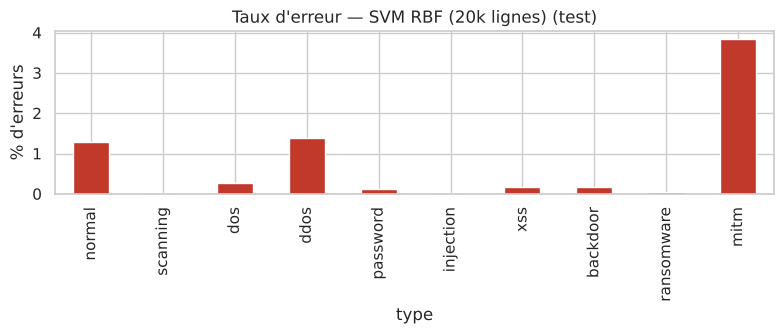

In [14]:
err = pd.DataFrame({"type": y_te["type"].to_numpy(), "label": yte, "pred": pred["Seuil calibré (F1 valid)"]}); err["erreur"] = err.label != err.pred
by_type = err.groupby("type").agg(n=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean")).loc[U.TYPE_ORDER]; display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5)); by_type["taux_erreur"].mul(100).plot(kind="bar", ax=ax, color="#c0392b"); ax.set_ylabel("% d'erreurs"); ax.set_title(f"Taux d'erreur — {retained} (test)")
plt.tight_layout(); U.savefig(fig, "03_error_by_type"); plt.show()

## 10. Sauvegarde

In [15]:
joblib.dump(final, U.MODEL_DIR / "svm_anomaly.joblib", compress=3)
sel = test_tbl.loc["Seuil calibré (F1 valid)"]
U.save_result("03_svm_anomaly", {
    "task": "Détection d'anomalies", "model": f"SVM ({retained})", "balancing": best_strategy, "params": {"linear_C": best_C, **{f"rbf_{k}": v for k, v in best_rbf.items()}},
    "threshold": thr, "fit_time_s": fit_times[retained], "valid_f1": f1_thr, "test": {k: float(v) for k, v in sel.items()},
    "test_default_threshold": {k: float(v) for k, v in test_tbl.loc["Marge > 0 (défaut)"].items()}, "brier_test": brier.to_dict(),
    "variants_valid": cmp_.round(5).to_dict("index"), "balancing_cv": bal.round(5).to_dict("index"), "error_by_type": by_type["taux_erreur"].to_dict()})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


## Conclusion (SVM — détection d'anomalies)

- Trois SVM comparés sur la **même validation** : linéaire (rapide, interprétable), RBF exact (non linéaire mais limité à un sous-échantillon), Nyström + linéaire (RBF approché sur tout le train).
- Le seuil est déplacé sur la **marge de décision** et les scores sont transformés en probabilités (Platt / isotonique).
- Le test n'est lu qu'**une seule fois**. Les valeurs chiffrées sont dans le §8 et dans le notebook 06.